In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Mall_Customers.csv to Mall_Customers.csv


In [ ]:
data = pd.read_csv('Mall_Customers.csv')
data.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [ ]:
data.shape

(200, 5)

In [ ]:
data.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [ ]:
data.dtypes

,0
CustomerID,int64
Gender,object
Age,int64
Annual Income (k$),int64
Spending Score (1-100),int64


In [ ]:
data.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


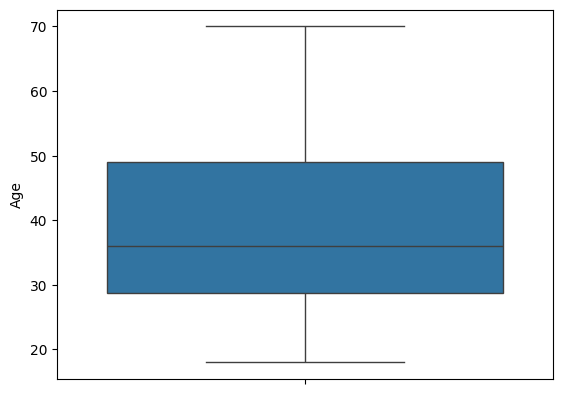

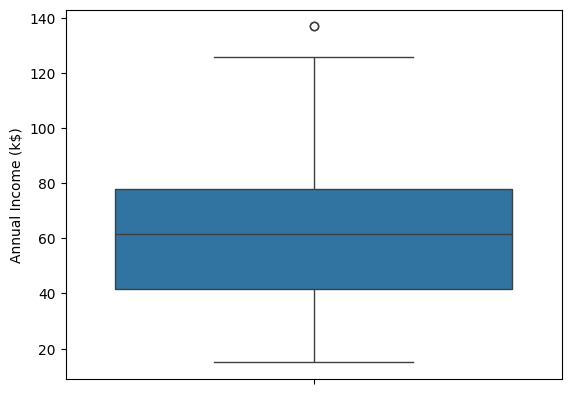

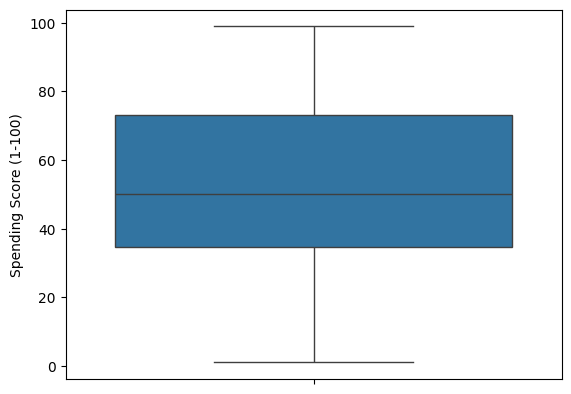

In [ ]:
columns = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
for i in columns:
  sns.boxplot(data[i])
  plt.show()

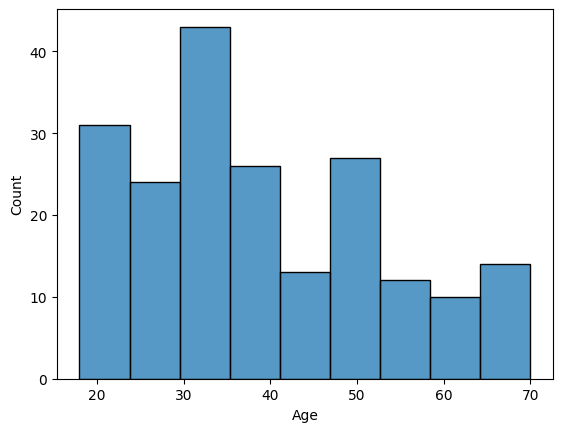

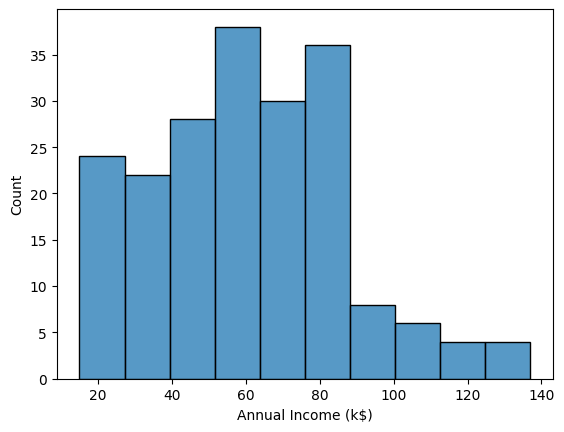

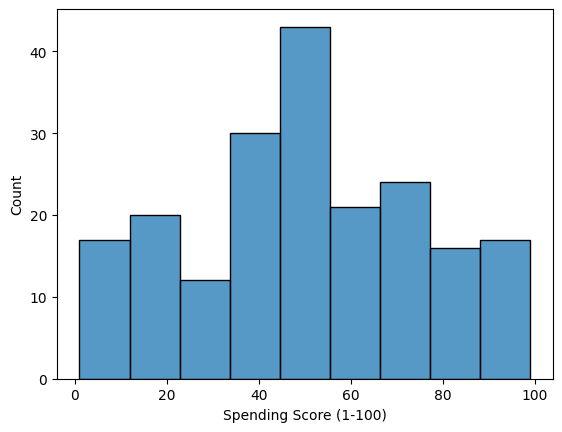

In [ ]:
for i in columns:
  sns.histplot(data[i])
  plt.show()

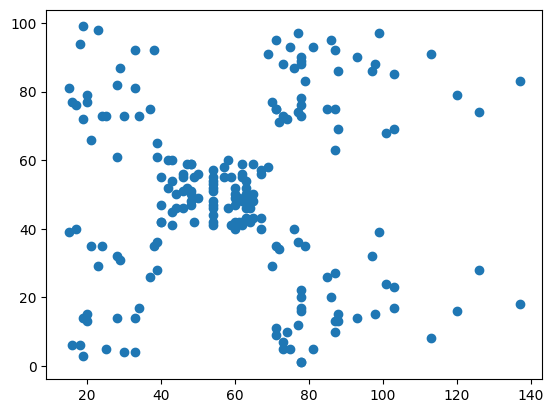

In [ ]:
plt.scatter(data['Annual Income (k$)'], data['Spending Score (1-100)'])

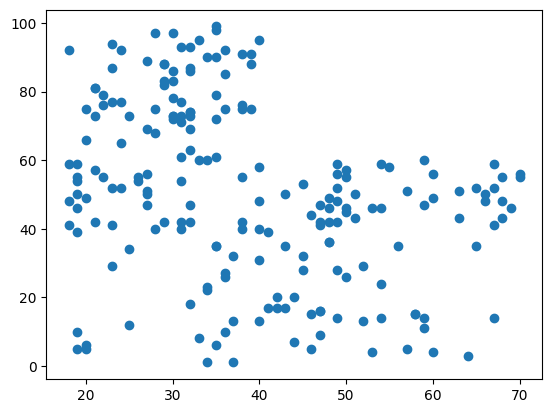

In [ ]:
plt.scatter(data['Age'], data['Spending Score (1-100)'])

In [ ]:
data_encoded = pd.get_dummies(data)
data_encoded.head()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Gender_Female,Gender_Male
0,1,19,15,39,False,True
1,2,21,15,81,False,True
2,3,20,16,6,True,False
3,4,23,16,77,True,False
4,5,31,17,40,True,False


<Axes: >

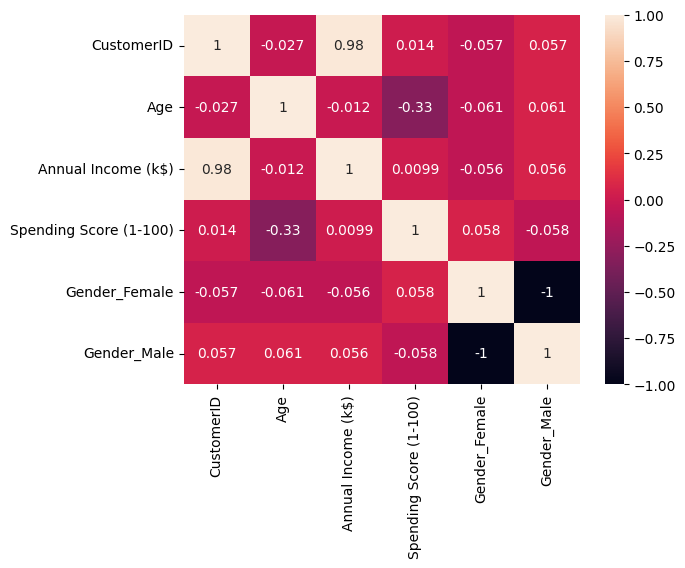

In [ ]:
sns.heatmap(data_encoded.corr(), annot=True)

In [ ]:
features = data_encoded[['Annual Income (k$)', 'Spending Score (1-100)']]
features.head(10)

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40
5,17,76
6,18,6
7,18,94
8,19,3
9,19,72


In [ ]:
#Model train:
wcss = []

for k in range(1, 11):
  kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
  kmeans.fit(features)
  wcss.append(kmeans.inertia_)

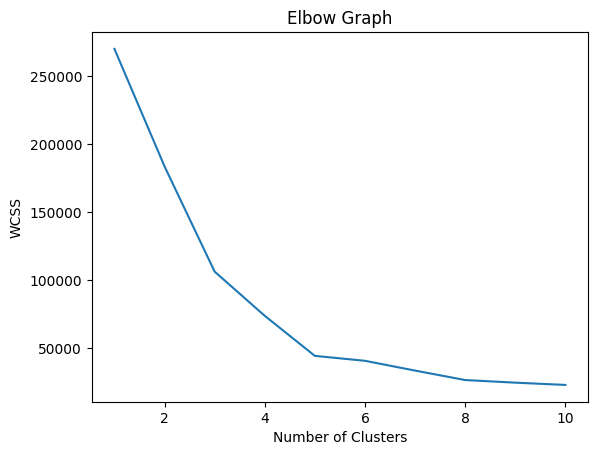

In [ ]:
plt.plot(range(1, 11), wcss)

plt.title("Elbow Graph")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")

plt.show()

In [ ]:
best_k = 5

kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
labels = kmeans.fit_predict(features)

In [ ]:
#fetures convrt into array:
features = data_encoded[['Annual Income (k$)', 'Spending Score (1-100)']].values

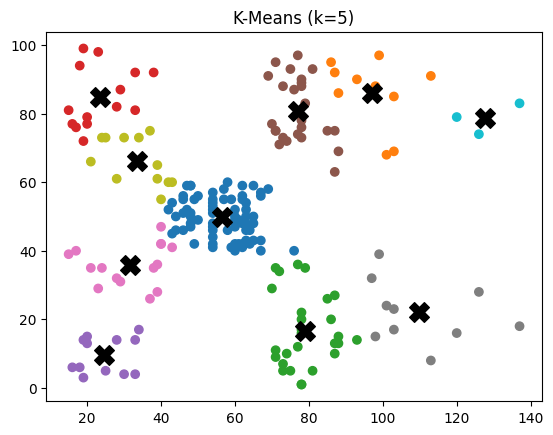

In [ ]:
plt.scatter(features[:,0], features[:,1], c=labels, cmap='tab10')
plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    c='black', s=200, marker='X'
)
plt.title(f'K-Means (k={best_k})')
plt.show()


In [ ]:
from sklearn.metrics import silhouette_score

score = silhouette_score(features, labels)
print(f'Silhouette Score:', score)

Silhouette Score: 0.4426214845978157


In [ ]:
from sklearn.metrics import calinski_harabasz_score
calinski_harabasz_score(features, labels)

np.float64(225.59168424215443)

In [ ]:
from sklearn.metrics import davies_bouldin_score
davies_bouldin_score(features, labels)

np.float64(0.8084809590032913)

In [ ]:
data_clustered = data_encoded.copy()
data_clustered['Cluster'] = labels
data_clustered.head()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Gender_Female,Gender_Male,Cluster
0,1,19,15,39,False,True,6
1,2,21,15,81,False,True,3
2,3,20,16,6,True,False,4
3,4,23,16,77,True,False,3
4,5,31,17,40,True,False,6
